# Анализ и прогнозирование временных рядов методами искусственного интеллекта

## **Практическая работа 6. Поиск эволюционирующих шаблонов с помощью матричного профиля ряда.**

In [1]:
%load_ext autoreload
%autoreload 2

## **Часть 1.** Поиск цепочек временного ряда.

Импорт библиотек и модулей

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import stumpy
from sklearn.metrics import mean_squared_error

В первом задании вам предстоит выполнить поиск эволюционирующих шаблонов временного ряда. Выполните считывание набора данных [Rotation Matrix](datasets/Rotation%20Matrix.txt), найдите в нем самую длинную цепочку и выведите индексы начала звеньев этой цепочки.

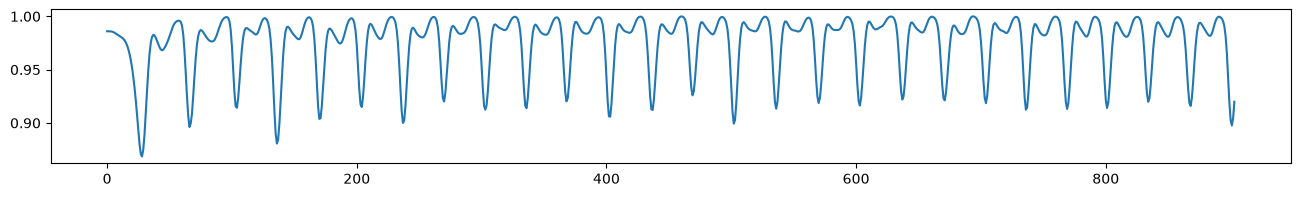

In [3]:
fig, ax = plt.subplots(figsize=(16, 2))
ts = np.loadtxt('datasets/Rotation Matrix.txt')
ax.plot(ts)

In [4]:
m = 85
mp = stumpy.stump(ts, m=m)

result = stumpy.allc(mp[:, 2], mp[:, 3])

if isinstance(result, tuple):
    chain = np.asarray(result[1]).astype(int).ravel()
else:
    chain = np.asarray(result).astype(int).ravel()

print("Индексы начала звеньев самой длинной цепочки:")
print(chain)
print(f"\nКоличество звеньев в цепочке: {len(chain)}")

Индексы начала звеньев самой длинной цепочки:
[  7  45 114 480 514 581]

Количество звеньев в цепочке: 6


❓ Проанализируйте и изложите содержательный смысл полученных результатов.

Полученный массив содержит индексы начала подпоследовательностей, образующих самую длинную цепочку временного ряда. Каждое звено цепочки представляет собой подпоследовательность длиной 85 элементов.

Для построения цепочки используются индексы ближайших соседей слева и справа, полученные с помощью матричного профиля. Звенья соединяются в цепочку, если они являются взаимными ближайшими соседями в соответствующих направлениях.

Таким образом, полученная цепочка состоит из похожих подпоследовательностей, расположенных в хронологическом порядке, форма которых постепенно изменяется со временем.

## **Часть 2. Визуализация цепочек**

Выполните визуализацию найденных в прошлом задании цепочек: постройте график временного ряда, на котором выделены звенья цепочек. Также постройте график, на котором изображены только сами звенья.

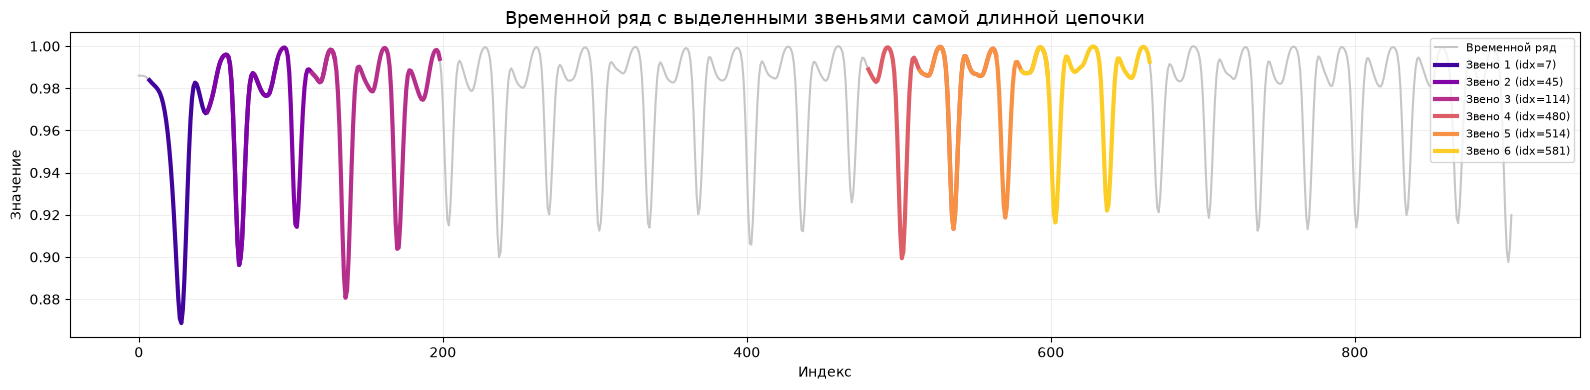

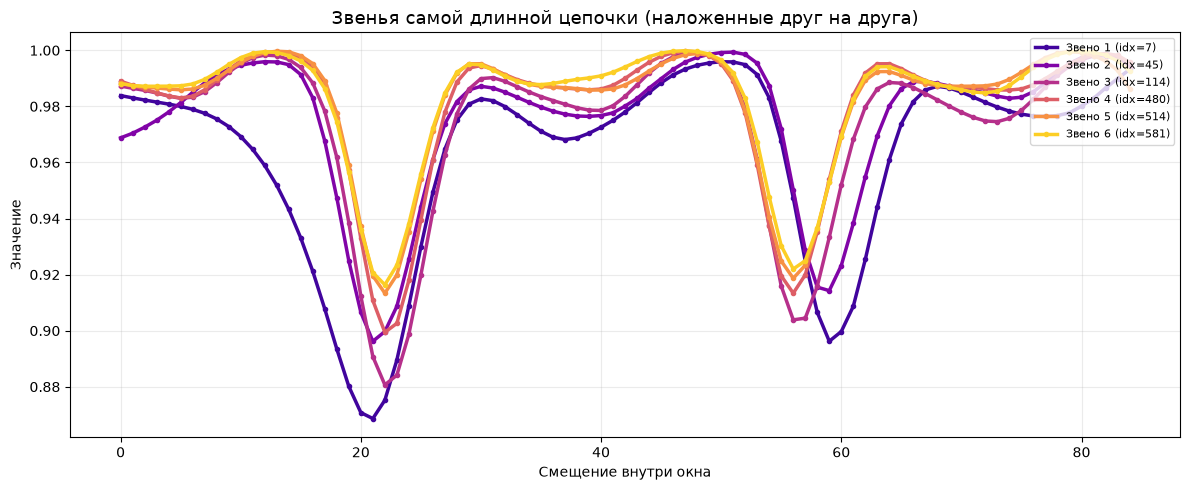

In [7]:
# Визуализация найденных цепочек

# Палитра цветов
colors = plt.cm.plasma(np.linspace(0.1, 0.9, len(chain)))

# График 1: временной ряд с выделенными звеньями цепочки
fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(ts, color='silver', linewidth=1.5, alpha=0.9, label='Временной ряд')

for i, idx in enumerate(chain):
    ax.plot(range(idx, idx + m), ts[idx:idx + m],
            color=colors[i], linewidth=3,
            label=f'Звено {i+1} (idx={idx})')

ax.set_title('Временной ряд с выделенными звеньями самой длинной цепочки', fontsize=13)
ax.set_xlabel('Индекс')
ax.set_ylabel('Значение')
ax.legend(loc='upper right', fontsize=8, frameon=True)
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()


# График 2: наложение самих звеньев цепочки
fig, ax = plt.subplots(figsize=(12, 5))

for i, idx in enumerate(chain):
    ax.plot(range(m), ts[idx:idx + m],
            color=colors[i], linewidth=2.5,
            marker='o', markersize=3,
            label=f'Звено {i+1} (idx={idx})')

ax.set_title('Звенья самой длинной цепочки (наложенные друг на друга)', fontsize=13)
ax.set_xlabel('Смещение внутри окна')
ax.set_ylabel('Значение')
ax.legend(loc='upper right', fontsize=8, frameon=True)
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

❓ Проанализируйте и изложите содержательный смысл полученных результатов.

На первом графике показано расположение звеньев найденной цепочки в исходном временном ряду. Можно заметить, что звенья расположены последовательно по времени, но между ними могут присутствовать промежутки.

На втором графике звенья наложены друг на друга, что позволяет сравнить их форму. Видно, что подпоследовательности имеют схожую структуру, однако от одного звена к следующему их форма постепенно изменяется. При этом различия между первым и последним звеном становятся более заметными.

## **Часть 3.** Предсказывание значений ряда на основе цепочек.

Предскажите значения последнего звена цепочки, вычислив разность между двумя предыдущими звеньями цепочки. Сравните полученное предсказание с истинным значением.

Среднеквадратичная ошибка (MSE) предсказания: 0.000027
Среднеквадратичное отклонение истинного звена: 0.0216
Нормализованная ошибка: 0.0571


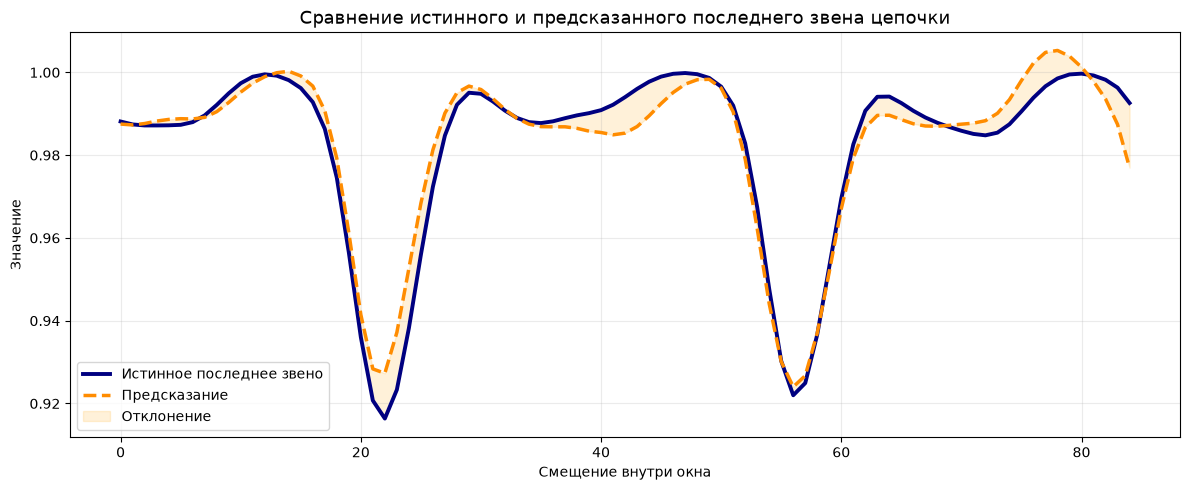

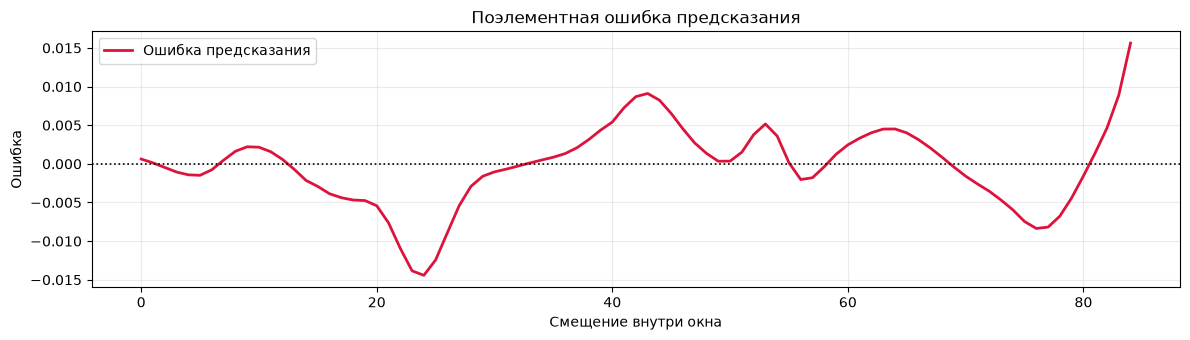

In [8]:
# Предсказание значений последнего звена цепочки
# на основе разности двух предыдущих звеньев

# Берём три последних звена цепочки
last_chain = chain[-3:]
idx_prev2, idx_prev1, idx_last = last_chain

# Истинные значения последнего звена
y_true = ts[idx_last:idx_last + m]

# Предсказание: разность между двумя предыдущими звеньями
y_pred = ts[idx_prev1:idx_prev1 + m] + (ts[idx_prev1:idx_prev1 + m] - ts[idx_prev2:idx_prev2 + m])

# Метрики
mse = mean_squared_error(y_true, y_pred)
print(f"Среднеквадратичная ошибка (MSE) предсказания: {mse:.6f}")
print(f"Среднеквадратичное отклонение истинного звена: {np.std(y_true):.4f}")
print(f"Нормализованная ошибка: {mse / np.var(y_true):.4f}")

# Визуализация предсказания
fig, ax = plt.subplots(figsize=(12, 5))

x = range(m)

ax.plot(x, y_true,
        label='Истинное последнее звено',
        linewidth=2.8,
        color='navy')

ax.plot(x, y_pred,
        label='Предсказание',
        linewidth=2.5,
        color='darkorange',
        linestyle='--')

ax.fill_between(x, y_true, y_pred, color='orange', alpha=0.15, label='Отклонение')

ax.set_title('Сравнение истинного и предсказанного последнего звена цепочки', fontsize=13)
ax.set_xlabel('Смещение внутри окна')
ax.set_ylabel('Значение')
ax.legend(frameon=True)
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()


# График поэлементной ошибки
fig, ax = plt.subplots(figsize=(12, 3.5))

error = y_true - y_pred
ax.plot(x, error, color='crimson', linewidth=2, label='Ошибка предсказания')
ax.axhline(0, color='black', linestyle=':', linewidth=1.2)

ax.set_title('Поэлементная ошибка предсказания', fontsize=12)
ax.set_xlabel('Смещение внутри окна')
ax.set_ylabel('Ошибка')
ax.legend(frameon=True)
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

❓ Проанализируйте и изложите содержательный смысл полученных результатов.

Для прогнозирования последнего звена цепочки была рассчитана разность между двумя предыдущими звеньями. Полученная разность прибавлялась к предпоследнему звену, что позволило предсказать значения последнего.

По графику видно, что предсказанные значения достаточно близки к реальным. Нормализованная среднеквадратичная ошибка составила 0.0571, что говорит о хорошей точности прогноза относительно изменчивости исходного сигнала.

Таким образом, можно сделать вывод, что форма шаблона изменяется достаточно плавно, благодаря чему предыдущие звенья цепочки можно использовать для краткосрочного прогнозирования. Однако при прогнозировании на более далёкое будущее точность может снижаться.